In [1]:
import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')

import astropy.units as u
import numpy as np

from params import p_cosmology, p
from transient_rates import plot_rates, R_SFR, R_sGRB, R_TDE
from transient_lumonosity import get_N_k_firesong, get_phi_z1, get_phi, get_E_nu_iso

We will compute the flux constant $\phi_k(z)$ for supernovae CC Ibc, supernovae CC IIn, tidal disruption events, and kilonovae.

In [2]:
time_window = 1 * u.yr
z_max = 10
print(f'Considering a time window of {time_window} and a max z = {z_max}\n')

#Ibc
n_Ibc = get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['SN Ib/c'], time_window=1*u.yr, z_max=z_max)
phi_k_1_Ibc = get_phi_z1(R_SFR, R0=p_cosmology['R0']['SN Ib/c'], z_max=z_max)
E_nu_iso_Ibc = get_E_nu_iso(phi_k_1_Ibc).to(u.erg * u.s **-1)

print("N_tot SN Ibc: ", np.format_float_scientific(n_Ibc))
print("Ibc -> phi_k(z = 1): ", phi_k_1_Ibc)
print("Ibc -> E_nu_iso: ", E_nu_iso_Ibc, "\n")

#II
n_II = get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['SN II'], time_window=1*u.yr, z_max=z_max)
phi_k_1_II = get_phi_z1(R_SFR, R0=p_cosmology['R0']['SN II'], z_max=z_max)
E_nu_iso_II = get_E_nu_iso(phi_k_1_II).to(u.erg * u.s **-1)

print("N_tot SN II: ", np.format_float_scientific(n_II))
print("II -> phi_k(z = 1): ", phi_k_1_II)
print("II -> E_nu_iso: ", E_nu_iso_II, "\n")

#TDE
n_TDE = get_N_k_firesong(R_TDE, R0=p_cosmology['R0']['TDE'], time_window=1*u.yr, z_max=z_max)
phi_k_1_TDE = get_phi_z1(R_TDE, R0=p_cosmology['R0']['TDE'], z_max=z_max)
E_nu_iso_TDE = get_E_nu_iso(phi_k_1_TDE).to(u.erg * u.s **-1)

print("N_tot TDE: ", np.format_float_scientific(n_TDE))
print("TDE -> phi_k(z = 1): ", phi_k_1_TDE)
print("TDE -> E_nu_iso: ", E_nu_iso_TDE, "\n")

#KN
n_KN = get_N_k_firesong(R_SFR, R0=p_cosmology['R0']['sGRB'], time_window=1*u.yr, z_max=z_max)
phi_k_1_KN = get_phi_z1(R_SFR, R0=p_cosmology['R0']['sGRB'], z_max=z_max)
E_nu_iso_KN = get_E_nu_iso(phi_k_1_KN).to(u.erg * u.s **-1)

print("N_tot KN: ", np.format_float_scientific(n_KN))
print("KN -> phi_k(z = 1): ", phi_k_1_KN)
print("KN -> E_nu_iso: ", E_nu_iso_KN, "\n")

Considering a time window of 1.0 yr and a max z = 10

N_tot SN Ibc:  1.0963721480167623e+08
Ibc -> phi_k(z = 1):  8.769377364225079e-24 1 / (GeV s cm2)
Ibc -> E_nu_iso:  1.6814403645483286e+43 erg / s 

N_tot SN II:  3.289116444050287e+08
II -> phi_k(z = 1):  2.9231257880750263e-24 1 / (GeV s cm2)
II -> E_nu_iso:  5.604801215161095e+42 erg / s 

N_tot TDE:  8.996679046065776e+04
TDE -> phi_k(z = 1):  1.2786669018607503e-22 1 / (GeV s cm2)
TDE -> E_nu_iso:  2.451715842873425e+44 erg / s 

N_tot KN:  2.57484627237204e+05
KN -> phi_k(z = 1):  3.734009754581505e-21 1 / (GeV s cm2)
KN -> E_nu_iso:  7.159590085134114e+45 erg / s 



In [3]:
def compute_neutrino_luminosities(transients=['SN Ib/c', 'SN II', 'TDE', 'sGRB'], p=p_cosmology,
                                  z_max=10, time_window=1*u.yr):
    '''
    Computes the neutrino luminosioties for a slect transients
    p: dict, from parasm.py
    transient_sel: list, transieents to compute the luminosity for. These should be keys for p_cosmology['R0']
    '''

    #define rate_functions to use for N_k
    #TO DO: put in params.py
    rate_functions = {
        'SN Ia': R_SFR,
        'SN II': R_SFR,
        'SN Ib/c': R_SFR,
        'TDE': R_TDE,
        'sGRB': R_sGRB
    }

    neutrino_luminosities = dict()

    for transient in transients:
        # n_k = get_N_k_firesong(rate_functions[transient],
        #                     R0=p_cosmology['R0'][transient], 
        #                     time_window=time_window, 
        #                     z_max=z_max)
        phi_z1_k = get_phi_z1(rate_functions[transient],
                            R0=p_cosmology['R0'][transient], 
                            z_max=z_max)
        E_nu_iso_k = get_E_nu_iso(phi_k_1_Ibc).to(u.erg * u.s **-1)
        neutrino_luminosities[transient] = {
            'phi_z1_k': phi_z1_k,
            'gamma': p['nu_diff_gamma'],
            'R0': p['R0'][transient],
            'E_nu_iso_k': E_nu_iso_k
        }
        
    return neutrino_luminosities

    
def write_luminosities_to_file(transient_luminosities, file_path='', p=p):
    '''
    Writes transient_luminosities to a csv file

    Params:
    -------
    transient_luminosities: dict of format: 
                            {'Ib': {
                                'phi_z1_k': 1e10 (in GeV^-1 s^-1 cm^-2, normalizatrion flux at z=1)
                                'gamma': 2.53 (spectral index)
                                'R0': 1e-8 (Local rate used to compute the transient, in Mpc^-3 yr^-1)
                                'E_nu_iso_k: (equivalent isotropic  eutrio energy, in erg/s)
                                }
                            }
    file_path: str, specific file to save the csv information. If not specified, we take it from params.py
    '''

    if file_path == '':
        file_path = p['neutrino_luminosity_path']

    columns = ['Transient', 'R0 (1 / Gpc^3 yr)', 'gamma', 'phi_z1 (1 / GeV s cm^2)', 'E_nu_iso (erg / s)']

    with open(file_path, 'w') as file:

        #header 
        file.write(','.join(columns) + '\n')
        for transient_type in transient_luminosities.keys():
            R0 = str(transient_luminosities[transient_type]['R0'].to(u.Gpc ** -3 * u.yr ** -1).value)
            gamma = str(transient_luminosities[transient_type]['gamma'])
            phi_z1 = str(transient_luminosities[transient_type]['phi_z1_k'].to(u.GeV ** -1 * u.s**-1 * u.cm ** -2).value)
            E_nu_iso = str(transient_luminosities[transient_type]['E_nu_iso_k'].to(u.GeV * u.s ** -1).value)
            file.write(','.join([transient_type, R0, gamma, phi_z1, E_nu_iso]) + '\n')

    return



In [4]:
transient_luminosities = compute_neutrino_luminosities()
write_luminosities_to_file(transient_luminosities)


### Comparison to Firesong

In [8]:
import pandas as pd
import astropy.units as u
df = pd.read_csv('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/bayesian analysis/neutrino_luminosities.csv')
df

,Transient,R0 (1 / Gpc^3 yr),gamma,phi_z1 (1 / GeV s cm^2),E_nu_iso (erg / s)
0,SN Ib/c,25250.0,-2.52,8.769377e-24,1.049473e+46
1,SN II,75750.0,-2.52,2.923126e-24,1.049473e+46
2,TDE,800.0,-2.52,1.278667e-22,1.049473e+46
3,sGRB,59.3,-2.52,9.977645e-22,1.049473e+46


In [ ]:
def read_luminosity_from_csv(path_csv, k):

    '''
    Reads trhe comp[uted luyminosity model from the csv file. It uses the functions in transient_luminosity to compute his originally
    '''
    df = pd.read_csv(path_csv)
    i = list(df['Transient']).index(k)
    luminosity = {
        'R0' : df['R0 (1 / Gpc^3 yr)'][i] * u.Gpc**-3  * u.yr**-1, 
        'gamma': df['gamma'][i],
        'phi_z1': df['phi_z1 (1 / GeV s cm^2)'][i] * u.GeV ** -1 * u.s ** -1 * u.cm ** -2,
        'E_nu_iso': df['E_nu_iso (erg / s)'][i] * u.erg * u.s ** -1,
    }
    return luminosity
    

In [16]:
read_luminosity_from_csv('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/bayesian analysis/neutrino_luminosities.csv', k='sGRB')

{'R0': <Quantity 59.3 1 / (yr Gpc3)>,
 'gamma': np.float64(-2.52),
 'phi_z1': <Quantity 9.97764499e-22 1 / (GeV s cm2)>,
 'E_nu_iso': <Quantity 1.04947253e+46 erg / s>}

In [6]:
from firesong.Firesong import firesong_simulation

In [7]:
time = (100 * u.d).to(u.s).value
sim_values = firesong_simulation('./', density=1e-6, Evolution='CC2015SNR', zmax=10.0,
                    fluxnorm=1.44e-8, index=2.53, LF='SC', Transient=True, timescale=time,
                    filename=None)
sim_values

##############################################################################
##### FIRESONG initializing  - Calculating Neutrino CDFs #####
Standard candle sources+
Transient Sources, time scale = 8640000.0s
Source evolution assumed: CC2015SNR
Local density of neutrino sources: 1e-06/Mpc^3
Total number of neutrinos sources in the Universe: 2423376
Redshift range: 0 - 10.0
Standard Candle Luminosity: 7.2363e+50 erg/yr
##### FIRESONG initialization done #####

Actual diffuse flux simulated :
E^2 dNdE = 1.9299508085832975e-08 (E/100 TeV)^(-0.5299999999999998) [GeV/cm^2.s.sr]


{'header': {'LF': 'SC',
  'Transient': True,
  'timescale': np.float64(8640000.0),
  'fluxnorm': 1.44e-08,
  'delta_gamma': -0.5299999999999998,
  'luminosity': np.float64(7.236281583487355e+50)},
 'total_flux': np.float64(1.9299508085832975e-08),
 'sources': {'dec': array([-3.04755236e+01,  4.68159163e-02, -1.73870976e+01, ...,
         -8.25782086e+01,  4.14244510e+01,  1.99011861e+01],
        shape=(2423376,)),
  'ra': array([318.22630945, 255.19114902,  55.80580829, ..., 295.6930427 ,
          18.39570866, 169.23159846], shape=(2423376,)),
  'flux': array([1.54558281e-13, 5.31780196e-14, 2.05347218e-13, ...,
         8.03011187e-14, 3.01929087e-16, 4.17009163e-15], shape=(2423376,)),
  'z': array([0.97802385, 1.35340253, 0.8949397 , ..., 1.19544152, 5.88488835,
         2.8322675 ], shape=(2423376,))}}

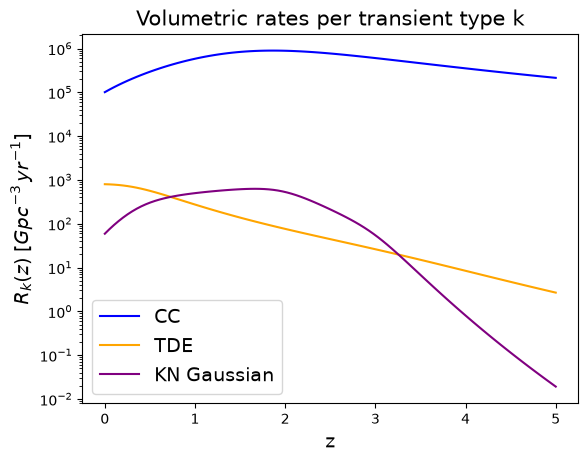

In [8]:
plot_rates(save_dir='/Users/cristozilleruelo/Desktop')